In [1]:
!pip3 install --upgrade statsmodels

     |████████████████████████████████| 9.5MB 5.1MB/s 
  Found existing installation: statsmodels 0.10.2
    Uninstalling statsmodels-0.10.2:
      Successfully uninstalled statsmodels-0.10.2


In [1]:
import os
from google.colab import drive
drive.mount('drive/')

Mounted at drive/


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import statsmodels

In [4]:
statsmodels.__version__

'0.12.1'

In [6]:
os.chdir('drive/My Drive/Complete_time_series/AutoRegressive/')

In [8]:
ls data

us_airline_carrier_passenger.csv


In [9]:
# load the data
df = pd.read_csv('./data/us_airline_carrier_passenger.csv')
df.head()

,month,passengers
0,2000-01-01,46492
1,2000-02-01,48526
2,2000-03-01,58764
3,2000-04-01,56033
4,2000-05-01,58201


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   month       240 non-null    object
 1   passengers  240 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 3.9+ KB


In [11]:
import datetime

In [12]:
df['month'] = pd.to_datetime(df['month'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   month       240 non-null    datetime64[ns]
 1   passengers  240 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 3.9 KB


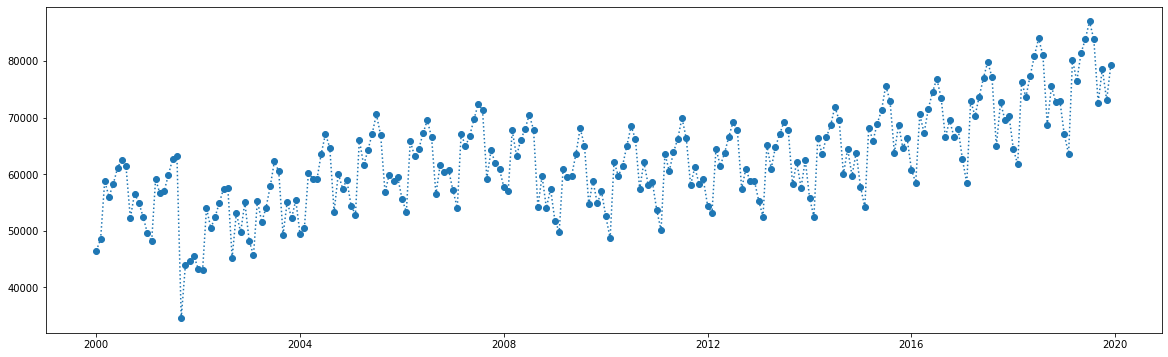

In [16]:
# visualize the data
plt.figure(figsize=(20,6))
plt.plot(df['month'],df['passengers'],'o:')

**Spliting the data into train and test**

- train : upto 2016-Dec
- test : 2016-Dec to 2019-Dec

In [23]:
df_train = df[df['month'] <= datetime.datetime.strptime('2016-12-01',"%Y-%m-%d")]
df_test = df[df['month'] > datetime.datetime.strptime('2016-12-01',"%Y-%m-%d")]

In [22]:
df_train.tail()

,month,passengers
199,2016-08-01,73450
200,2016-09-01,66477
201,2016-10-01,69539
202,2016-11-01,66591
203,2016-12-01,67983


In [24]:
df_test.head()

,month,passengers
204,2017-01-01,62621
205,2017-02-01,58377
206,2017-03-01,72962
207,2017-04-01,70262
208,2017-05-01,73679


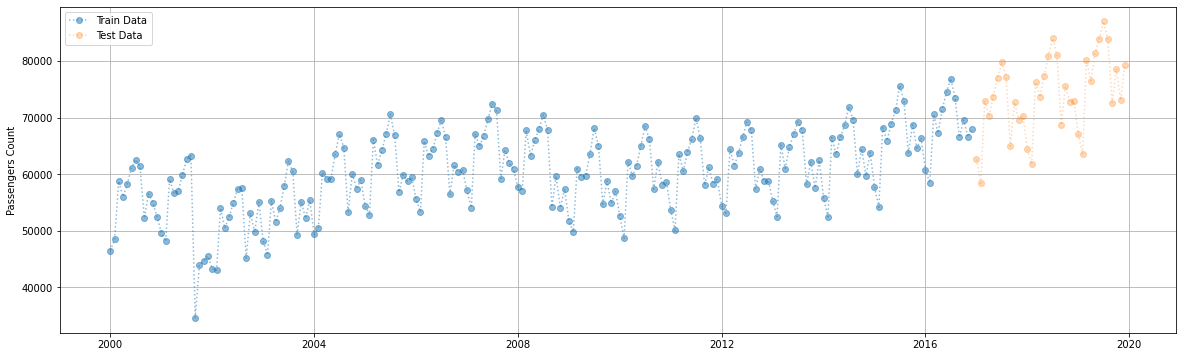

In [30]:
plt.figure(figsize=(20,6))
plt.plot(df_train['month'],df_train['passengers'],'o:',alpha=0.5)
plt.plot(df_test['month'],df_test['passengers'],'o:',alpha=0.3)

plt.legend(['Train Data','Test Data'])
plt.ylabel('Passengers Count')
plt.grid()
plt.show()

### **ACF and PACF**


In [31]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

Text(0.5, 0, 'Lags')

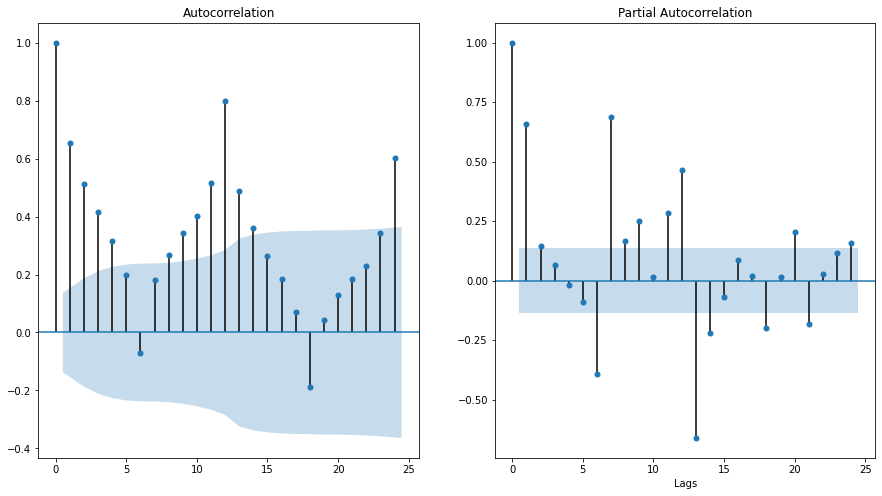

In [35]:
fig,ax = plt.subplots(nrows=1,ncols=2,figsize=(15,8))
res1 = plot_acf(df_train['passengers'],ax=ax[0])
plt.xlabel('Lags')
res2 = plot_pacf(df_train['passengers'],ax=ax[1])
plt.xlabel('Lags')

**Making Data Stationary**

In [38]:
difference = df_train['passengers'].diff()

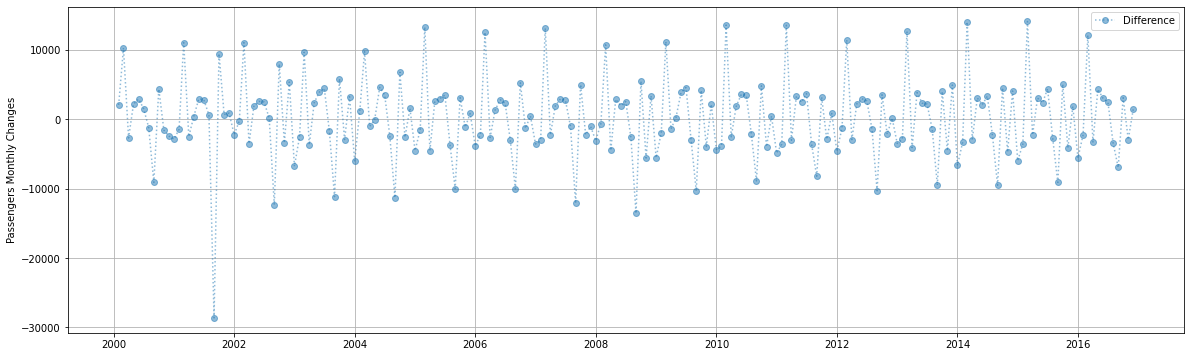

In [39]:
plt.figure(figsize=(20,6))
plt.plot(df_train['month'],difference,'o:',alpha=0.5)

plt.legend(['Difference'])
plt.ylabel('Passengers Monthly Changes')
plt.grid()
plt.show()

In [41]:
difference.dropna(inplace=True) # drop the missing before computing ACF and PACF

Text(0.5, 0, 'Lags')

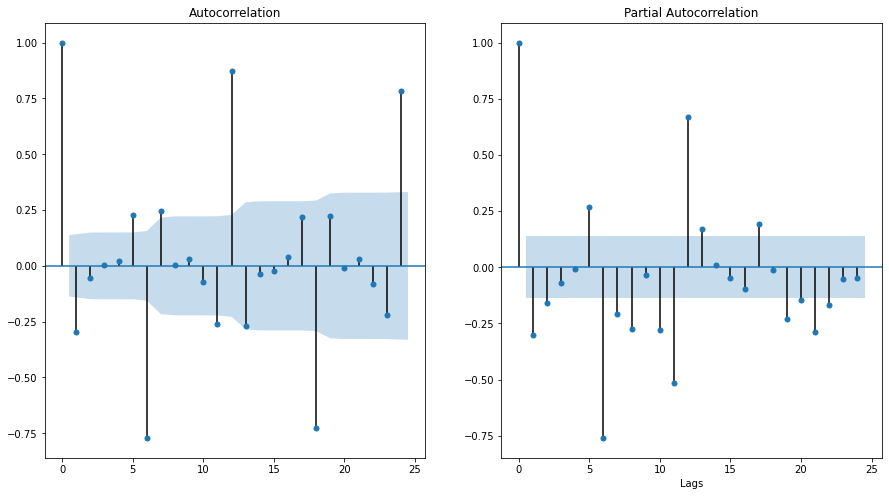

In [42]:
fig,ax = plt.subplots(nrows=1,ncols=2,figsize=(15,8))
res1 = plot_acf(difference,ax=ax[0])
plt.xlabel('Lags')
res2 = plot_pacf(difference,ax=ax[1])
plt.xlabel('Lags')

> **Clear Seasonality at 12 periods**

## Auto Regressive Model
- AR (p)

p = number of lags
- find p using PACF (find the number of lags which are not zero)

- 12 lags from PACF

AR(12)

In [45]:
x_train = df_train.set_index('month')
x_test = df_test.set_index('month')

In [46]:
from statsmodels.tsa.ar_model import AutoReg

In [47]:
model_ar = AutoReg(x_train,lags=12).fit()

/usr/local/lib/python3.6/dist-packages/statsmodels/tsa/base/tsa_model.py:527: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  % freq, ValueWarning)
/usr/local/lib/python3.6/dist-packages/statsmodels/tsa/ar_model.py:252: FutureWarning: The parameter names will change after 0.12 is released. Set old_names to False to use the new names now. Set old_names to True to use the old names. 
  FutureWarning,


In [48]:
print(model_ar.summary())

                            AutoReg Model Results                             
Dep. Variable:             passengers   No. Observations:                  204
Model:                    AutoReg(12)   Log Likelihood               -1791.208
Method:               Conditional MLE   S.D. of innovations           2725.128
Date:                Mon, 21 Dec 2020   AIC                             15.966
Time:                        17:04:53   BIC                             16.204
Sample:                    01-01-2001   HQIC                            16.063
                         - 12-01-2016                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
intercept      -1101.8877   2670.461     -0.413      0.680   -6335.894    4132.119
passengers.L1      0.4234      0.062      6.848      0.000       0.302       0.545
passengers.L2      0.0487      0.069

In [49]:
# fitted values
fittedvalues = model_ar.fittedvalues

In [50]:
fittedvalues.head()

month
2001-01-01    49334.710929
2001-02-01    49964.903006
2001-03-01    57480.606603
2001-04-01    55642.948449
2001-05-01    57963.182409
dtype: float64

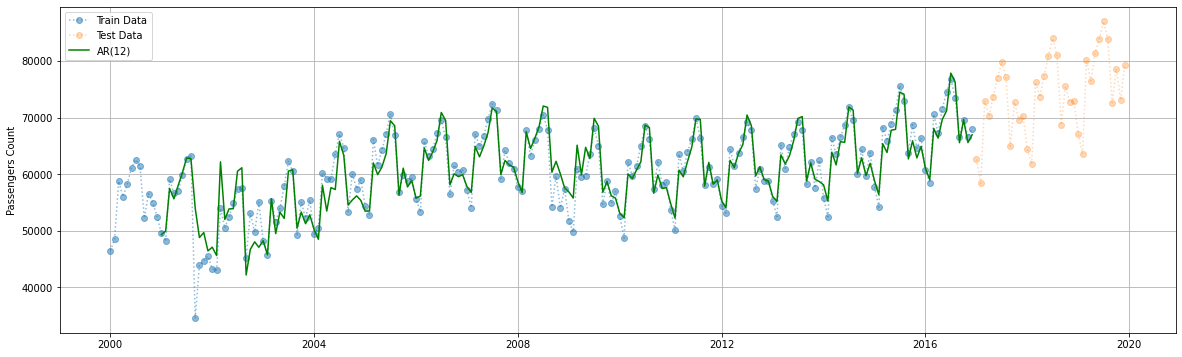

In [52]:
plt.figure(figsize=(20,6))
plt.plot(df_train['month'],df_train['passengers'],'o:',alpha=0.5)
plt.plot(df_test['month'],df_test['passengers'],'o:',alpha=0.3)
# fitted values
plt.plot(fittedvalues,'g-')

plt.legend(['Train Data','Test Data','AR(12)'])
plt.ylabel('Passengers Count')
plt.grid()
plt.show()

In [53]:
start = datetime.datetime.strptime('2017-01-01','%Y-%m-%d')
end = datetime.datetime.strptime('2019-12-01','%Y-%m-%d')
forecast_values = model_ar.predict(start,end)

/usr/local/lib/python3.6/dist-packages/statsmodels/tsa/deterministic.py:152: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Int64Indexes with a unit increment support extending. The index is set will contain the position relative to the data length.
  UserWarning,


In [55]:
forecast_values.head(3)

2017-01-01    63865.557371
2017-02-01    63222.994100
2017-03-01    70781.913370
Freq: MS, dtype: float64

In [58]:
ME = 1.96 * model_ar.resid.std()

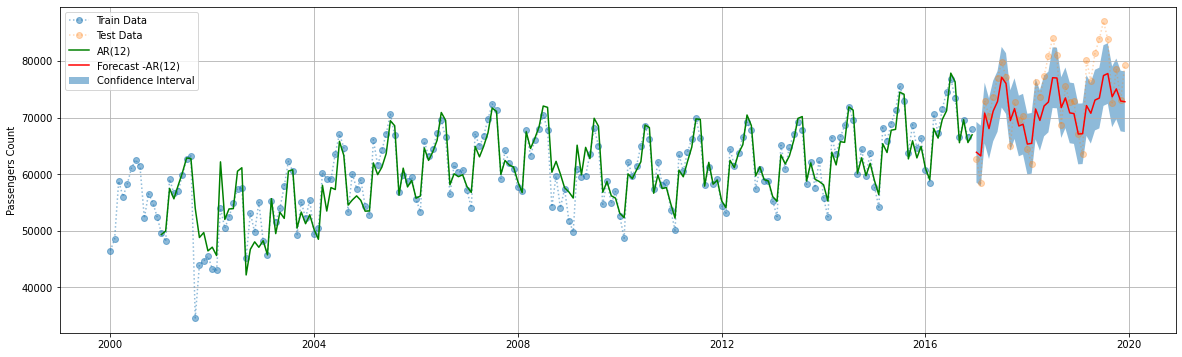

In [61]:
plt.figure(figsize=(20,6))
plt.plot(df_train['month'],df_train['passengers'],'o:',alpha=0.5)
plt.plot(df_test['month'],df_test['passengers'],'o:',alpha=0.3)
# fitted values
plt.plot(fittedvalues,'g-')
# forecasted values
plt.plot(forecast_values,'r-')
# confidence
plt.fill_between(df_test['month'],(forecast_values.values+ME),((forecast_values.values-ME)),alpha=0.5)

plt.legend(['Train Data','Test Data','AR(12)','Forecast -AR(12)','Confidence Interval'])
plt.ylabel('Passengers Count')
plt.grid()
plt.show()

**Evaluation**

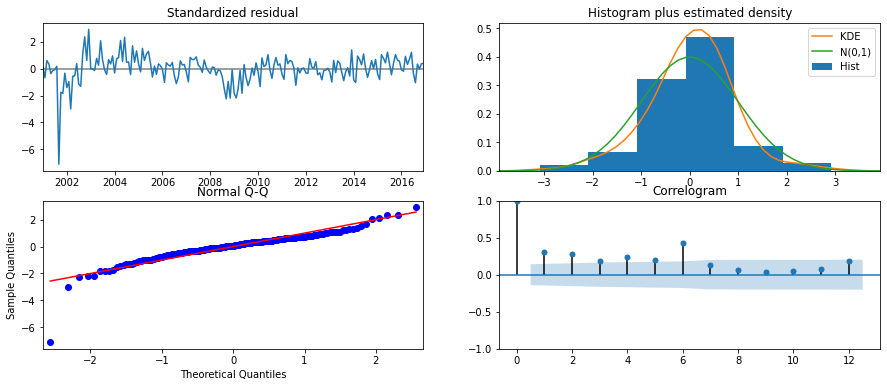

In [64]:
fig = plt.figure(figsize=(15,6))
fig =model_ar.plot_diagnostics(lags=12,fig=fig)